# 04 — Analisis Bivariat dan Multivariat
### Milestone M3 (dinilai saat UTS) · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | DANVA |
| **Anggota** | Diyanatul Fauziyah, Nasya Awaliyah, Raveska Hinayah, Asysyifa Ainaya Zahra |
| **Topik proyek** | Analisis Pola Penjualan Supermarket Berdasarkan Produk, Kota, Pelanggan, dan Metode Pembayaran |
| **Tanggal** | 15 November 2026 |

**Notebook ini mengisi:** dimensi **Analisis bivariat dan multivariat** (25), **Ketepatan teknik dan asumsi** (15), dan **Interpretasi** (25) pada Rubrik M3.

Bagian dengan bobot terbesar di M3. Lima hal di bawah **wajib** ada:

1. satu heatmap korelasi Pearson dan Spearman berdampingan dengan skala warna yang sama;
2. dua scatter plot dari pasangan paling menarik, masing-masing dengan satu paragraf tafsiran;
3. satu crosstab yang dinormalkan per baris beserta Cramér's V-nya;
4. satu faceting, dengan keterangan apakah polanya berubah;
5. satu paragraf kandidat variabel perancu.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**. Notebook yang tidak dapat
> berjalan dari awal sampai akhir dianggap tidak memenuhi dimensi *ketepatan implementasi*.


In [9]:
from google.colab import drive

drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 60)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
DATA  = '#0E7490'
SOROT = '#C2410C'
REDUP = '#5B6672'

# Path relatif: mendukung notebook dijalankan dari folder notebooks/ atau akar proyek.
kandidat_akar = [Path.cwd(), Path.cwd().parent]
AKAR = next((p for p in kandidat_akar if (p / 'data' / 'processed' / '/content/drive/MyDrive/EDA sendiri/supermarket_sales - Sheet1.csv').exists()), None)
if AKAR is None:
    raise FileNotFoundError("data/processed/data_bersih.csv tidak ditemukan. Jalankan 02_cleaning.ipynb terlebih dahulu.")
RAW = AKAR / 'data' / 'raw'
PROCESSED = AKAR / 'data' / 'processed'
FIGURES = AKAR / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)


In [11]:
df = pd.read_csv(PROCESSED / '/content/drive/MyDrive/EDA sendiri/supermarket_sales - Sheet1.csv')
print(f'{df.shape[0]} baris x {df.shape[1]} kolom')


1000 baris x 17 kolom


## 1. Heatmap korelasi — untuk memilih, bukan untuk menyimpulkan

Skala warna **wajib** sama di kedua panel (`vmin=-1, vmax=1, center=0`); tanpa itu kedua
panel tidak dapat dibandingkan.

Catatan: `.corr()` membuang baris kosong **per pasangan kolom**, sehingga setiap kotak
dihitung dari jumlah baris yang berbeda. Karena itu jangan mencantumkan satu angka n
pada judul heatmap.

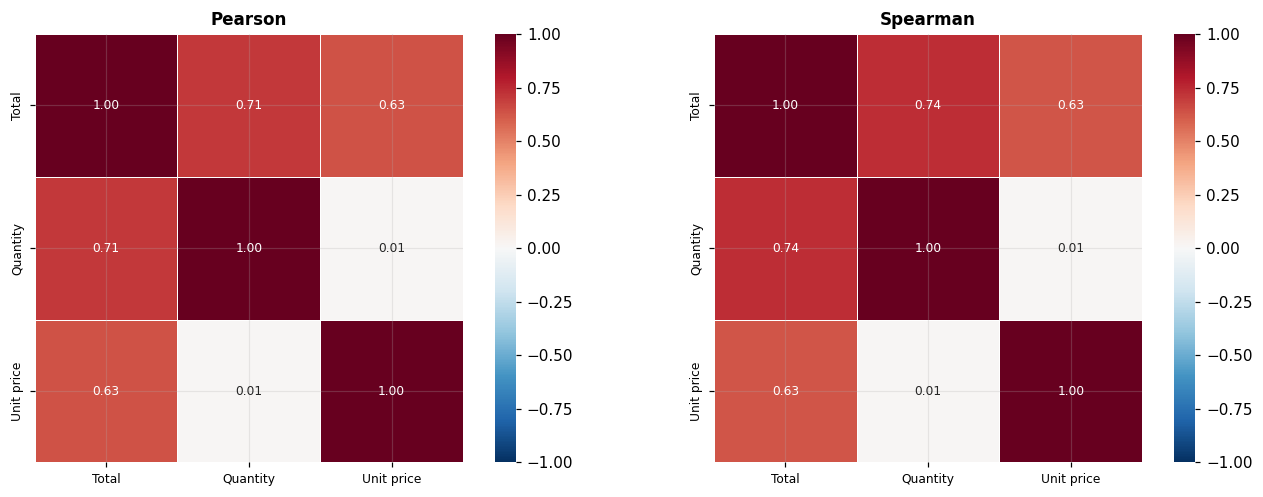

In [12]:
NUM = ['Total', 'Quantity', 'Unit price']

P = df[NUM].corr('pearson')
S = df[NUM].corr('spearman')

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, M, judul in [(axes[0], P, 'Pearson'), (axes[1], S, 'Spearman')]:
    sns.heatmap(M, ax=ax, annot=True, fmt='.2f', cmap='RdBu_r',
                vmin=-1, vmax=1, center=0, square=True,
                linewidths=.6, linecolor='white', annot_kws={'size': 8})
    ax.set_title(judul); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()


In [13]:
# Pasangan dengan selisih |Spearman - Pearson| terbesar: kandidat pertama untuk diperiksa.
D = (S - P).abs().to_numpy(copy=True)
np.fill_diagonal(D, np.nan)
i, j = np.unravel_index(np.nanargmax(D), D.shape)
print(f'Paling berbeda: {NUM[i]} vs {NUM[j]}  (selisih {D[i, j]:.3f})')
print('Selisih besar menandakan hubungan melengkung atau adanya outlier.')

Paling berbeda: Total vs Quantity  (selisih 0.030)
Selisih besar menandakan hubungan melengkung atau adanya outlier.


## 2. Scatter plot — selalu lihat gambarnya sebelum melaporkan angka

Aturan yang tidak boleh dilanggar: **jangan pernah melaporkan korelasi tanpa menampilkan
scatter plot-nya.**

In [14]:
def hubungan(a, b, kelompok=None):
    s = df[[a, b] + ([kelompok] if kelompok else [])].dropna()
    pr, pp = stats.pearsonr(s[a], s[b])
    sp, ps = stats.spearmanr(s[a], s[b])

    fig, ax = plt.subplots(figsize=(6.6, 4))
    if kelompok:
        for nama, g in s.groupby(kelompok):
            ax.scatter(g[a], g[b], s=18, alpha=.5, label=str(nama), edgecolor='none')
        ax.legend(frameon=False, fontsize=9, title=kelompok)
    else:
        ax.scatter(s[a], s[b], s=18, alpha=.4, color=DATA, edgecolor='none')
    ax.set_xlabel(a); ax.set_ylabel(b)
    ax.set_title(f'{a} vs {b}   n={len(s)}   Pearson {pr:.3f}   Spearman {sp:.3f}')
    plt.tight_layout(); plt.show()
    print(f'Pearson r={pr:.3f} (p={pp:.3g}); Spearman rho={sp:.3f} (p={ps:.3g})')
    print(f'selisih Spearman - Pearson = {sp-pr:+.3f}')
    return pr, sp



**Tafsiran pasangan 1 — Quantity dan Total.**

Terdapat hubungan positif kuat: Pearson r sekitar 0,704 dan Spearman rho sekitar 0,733
(pasangan data lengkap). Scatter plot menunjukkan kecenderungan total transaksi meningkat
ketika jumlah barang bertambah. Selisih kedua koefisien sekitar 0,029, kurang dari 0,05,
sehingga Pearson dapat dilaporkan untuk hubungan yang cukup linear; Spearman memberi
kesimpulan searah. Ini bukan bukti sebab-akibat, dan Total secara matematis memang
dibentuk dari harga satuan, kuantitas, serta pajak.


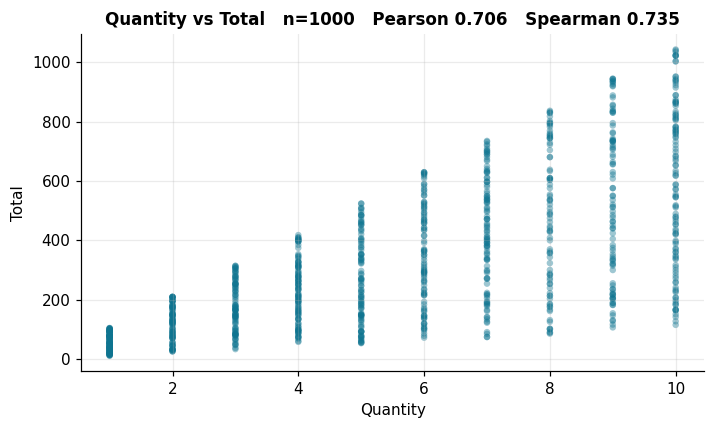

Pearson r=0.706 (p=2.06e-151); Spearman rho=0.735 (p=9.15e-171)
selisih Spearman - Pearson = +0.030


(np.float64(0.7055101859433064), np.float64(0.735265306019586))

In [15]:
# Pasangan 1: jumlah barang dan total transaksi
hubungan('Quantity', 'Total')


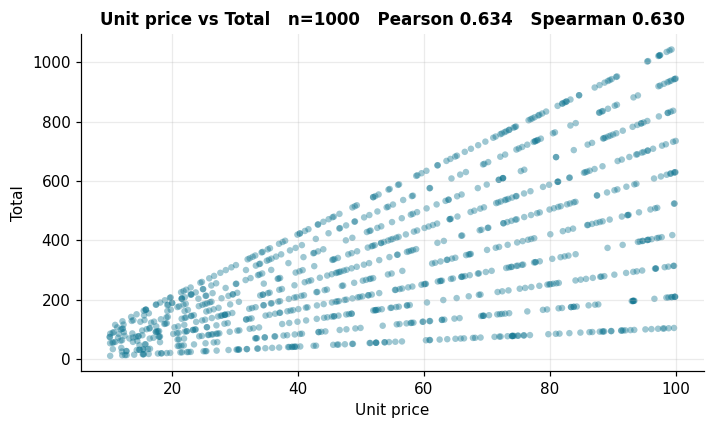

Pearson r=0.634 (p=1.61e-113); Spearman rho=0.630 (p=9.82e-112)
selisih Spearman - Pearson = -0.004


(np.float64(0.6339620885890692), np.float64(0.6300541064753133))

In [16]:
# Pasangan 2: harga satuan dan total transaksi
hubungan('Unit price', 'Total')


**Tafsiran pasangan 2 — Unit price dan Total.**

Terdapat hubungan positif kuat antara harga satuan dan total transaksi: Pearson r sekitar
0,634 dan Spearman rho sekitar 0,630. Selisihnya kecil (sekitar 0,004), sehingga Pearson
layak digunakan untuk merangkum hubungan yang tampak cukup linear pada scatter plot.
Hubungan ini sesuai secara perhitungan karena harga satuan merupakan salah satu komponen
pembentuk total transaksi. Hubungan ini tidak boleh ditafsirkan sebagai bukti kausalitas.


## 3. Asosiasi antarvariabel kategorikal

Crosstab dibaca dengan **persentase**, bukan hitungan mentah — hitungan mentah hanya
mencerminkan ukuran kategorinya.


In [17]:
def cramers_v(a, b, tampilkan=True):
    ct = pd.crosstab(a, b)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt((chi2 / ct.values.sum()) / (min(ct.shape) - 1))
    if tampilkan:
        print('PERSEN PER BARIS')
        print((pd.crosstab(a, b, normalize='index') * 100).round(1).to_string())
        print(f'\nchi2 = {chi2:.2f}   dof = {dof}   p = {p:.4f}   n = {ct.values.sum()}')
        print(f"Cramér's V = {v:.3f}")
    return round(v, 3)


In [18]:
# Asosiasi metode pembayaran dan tipe pelanggan\ncramers_v(df['Customer type'], df['Payment'])\n

**Tafsiran asosiasi kategorikal.**

Cramér's V sekitar 0,068 menunjukkan asosiasi praktis sangat lemah antara tipe pelanggan
(Member/Normal) dan metode pembayaran. p-value sekitar 0,102, sehingga pada taraf 5%
tidak terdapat bukti statistik yang cukup untuk menyatakan adanya asosiasi. Persentase
per baris pada crosstab tetap ditampilkan agar komposisi metode pembayaran di tiap tipe
pelanggan dapat dibandingkan. p-value bukan ukuran kekuatan hubungan.


## 4. Faceting — apakah polanya sama di setiap kelompok?

Tampilan yang paling sering dilewatkan, padahal paling sering menyelamatkan kesimpulan.
`sharex=True, sharey=True` adalah syarat: panel berdampingan dengan skala berbeda
menyesatkan meski tidak ada angka yang salah.


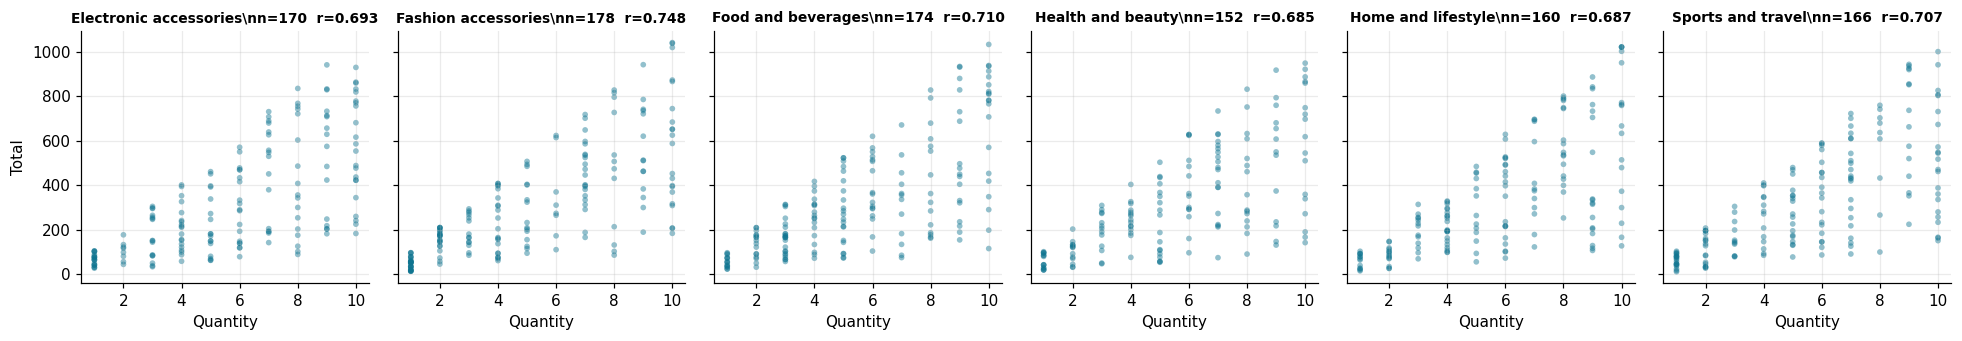

r gabungan: 0.706


In [19]:
X, Y, KELOMPOK = 'Quantity', 'Total', 'Product line'

s = df[[X, Y, KELOMPOK]].dropna()
kats = sorted(s[KELOMPOK].unique())
fig, axes = plt.subplots(1, len(kats), figsize=(3*len(kats), 3.2),
                         sharex=True, sharey=True)
for ax, k in zip(np.atleast_1d(axes), kats):
    sub = s[s[KELOMPOK] == k]
    ax.scatter(sub[X], sub[Y], s=14, alpha=.45, color=DATA, edgecolor='none')
    r = stats.pearsonr(sub[X], sub[Y])[0]
    ax.set_title(f'{k}\\nn={len(sub)}  r={r:.3f}', fontsize=9)
    ax.set_xlabel(X)
np.atleast_1d(axes)[0].set_ylabel(Y)
plt.tight_layout(); plt.show()
print(f'r gabungan: {stats.pearsonr(s[X], s[Y])[0]:.3f}')


**Tafsiran faceting.** Arah hubungan Quantity–Total tetap positif pada keenam lini produk.
Korelasi Pearson per lini berada sekitar 0,681–0,748, sedangkan korelasi gabungan sekitar
0,704. Tidak terlihat pembalikan arah, sehingga tidak ada indikasi Simpson's paradox pada
pengelompokan ini. Kekuatan hubungan sedikit berbeda antarproduk, tetapi pola umumnya
konsisten. Empat Quantity yang kosong otomatis tidak ikut dalam scatter/faceting.


## 5. Kandidat variabel perancu

Sebuah variabel Z disebut **perancu** bagi hubungan X–Y bila Z berkaitan dengan **keduanya**.
Tunjukkan kedua syaratnya dengan angka, masing-masing terpisah.

In [20]:
# Kandidat Z: Unit price untuk hubungan Quantity–Total.
# Syarat 1: Z (Unit price) berkaitan dengan X (Quantity).
s = df[['Unit price', 'Quantity']].dropna()
print("Unit price dengan Quantity:")
print("Pearson r =", round(stats.pearsonr(s['Unit price'], s['Quantity'])[0], 3))
print("Spearman rho =", round(stats.spearmanr(s['Unit price'], s['Quantity'])[0], 3))

# Syarat 2: Z (Unit price) berkaitan dengan Y (Total).
s2 = df[['Unit price', 'Total']].dropna()
print("\\nUnit price dengan Total:")
print("Pearson r =", round(stats.pearsonr(s2['Unit price'], s2['Total'])[0], 3))
print("Spearman rho =", round(stats.spearmanr(s2['Unit price'], s2['Total'])[0], 3))


Unit price dengan Quantity:
Pearson r = 0.011
Spearman rho = 0.011
\nUnit price dengan Total:
Pearson r = 0.634
Spearman rho = 0.63


**Paragraf kandidat variabel perancu.**

Untuk hubungan Quantity dan Total, Unit price merupakan variabel penting yang perlu
dipertimbangkan karena berkaitan kuat dengan Total (Pearson r = 0,634; Spearman rho = 0,630).
Namun, Unit price hampir tidak berkaitan dengan Quantity (Pearson r = 0,013; Spearman
rho sekitar 0,013). Dengan demikian, berdasarkan dua syarat pada data ini, Unit price
belum terbukti sebagai perancu yang memenuhi kedua hubungan sekaligus. Unit price tetap
perlu disebut sebagai komponen matematis pembentuk Total. Analisis observasional ini
tidak dapat membuktikan sebab-akibat atau menyingkirkan seluruh kemungkinan perancu.


## 6. Jawaban atas pertanyaan analisis

### Pertanyaan 1: Bagaimana hubungan jumlah barang dengan total penjualan per transaksi?
**Temuan:** Terdapat hubungan positif kuat antara Quantity dan Total (Pearson r = 0,704; Spearman rho = 0,733).
**Bukti:** Scatter plot Quantity–Total dan matriks korelasi; analisis menggunakan pasangan data lengkap.
**Keterbatasan:** Empat nilai Quantity kosong tidak ikut dihitung. Total secara matematis mencakup Quantity dan Unit price, sehingga hubungan ini bukan bukti sebab-akibat.

### Pertanyaan 2: Bagaimana hubungan harga satuan dengan total penjualan?
**Temuan:** Unit price berkorelasi positif kuat dengan Total (Pearson r = 0,634; Spearman rho = 0,630).
**Bukti:** Scatter plot Unit price–Total dan heatmap Pearson/Spearman.
**Keterbatasan:** Total dihitung dari komponen harga, kuantitas, dan pajak; hubungan ini bersifat matematis dan tidak membuktikan kausalitas.

### Pertanyaan 3: Apakah metode pembayaran berkaitan dengan tipe pelanggan?
**Temuan:** Asosiasi Customer type dan Payment sangat lemah (Cramér's V sekitar 0,068); p-value sekitar 0,102.
**Bukti:** Crosstab persentase per baris dan perhitungan Cramér's V.
**Keterbatasan:** Data hanya mencakup 1.000 transaksi pada tiga bulan dan tiga kota; hasil deskriptif tidak otomatis berlaku untuk periode atau supermarket lain.


> **Kalimat yang aman:** "Terdapat hubungan positif sedang antara X dan Y
> (Spearman rho = 0,57). Analisis ini tidak menunjukkan hubungan sebab-akibat;
> variabel Z berpotensi menjadi perancu karena berkaitan dengan keduanya."
>
> **Kalimat yang tidak boleh muncul:** "X menyebabkan kenaikan Y." · "Karena X naik, maka Y naik."
> Ganti kata kerjanya: *berkaitan dengan*, *cenderung disertai*.

## Checklist sebelum mengumpulkan

- [ ] Heatmap Pearson dan Spearman berdampingan dengan skala warna yang sama.
- [ ] Setiap angka korelasi yang dilaporkan disertai scatter plot-nya.
- [ ] Pilihan Pearson atau Spearman disertai alasan yang merujuk sifat data.
- [ ] Ada crosstab yang dinormalkan per baris beserta Cramér’s V-nya.
- [ ] Ada minimal satu faceting dengan `sharex=True, sharey=True`.
- [ ] Ada paragraf kandidat variabel perancu.
- [ ] Setiap pertanyaan analisis dari M1 dijawab, dengan bukti dan keterbatasannya.
- [ ] Tidak ada kalimat yang menyiratkan sebab-akibat.